In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Load DataSet

## EDA

In [2]:
df = pd.read_csv('demand_forecasting_data.csv')
df = df.drop(columns=['Product_ID'])
df.head()

,Date,Base_Sales,Marketing_Campaign,Marketing_Effect,Seasonal_Trend,Seasonal_Effect,Price,Discount,Competitor_Price,Stock_Availability,Public_Holiday,Demand
0,2019-01-01,65,Social Media,1.634270,Spring,1.0,73.496059,0.078198,64.173418,491,False,60570
1,2019-01-01,94,Social Media,1.240566,Summer,1.2,74.271862,0.182151,69.571391,135,True,18143
2,2019-01-01,125,Radio,1.087600,Summer,1.2,35.274616,0.102592,27.331268,180,False,37412
3,2019-01-01,128,TV,1.831657,Winter,0.8,79.524248,0.196125,73.429502,227,False,40773
4,2019-01-01,51,Radio,1.285161,Fall,1.1,96.237402,0.079253,88.243871,338,False,26917


### Date to Years And Months

In [3]:
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df = df.drop('Date', axis=1)

### DataSet Shape

In [4]:
df.shape

(35000, 13)

### Finding Null Values

In [5]:
df.isnull().sum()

Base_Sales               0
Marketing_Campaign    7067
Marketing_Effect         0
Seasonal_Trend           0
Seasonal_Effect          0
Price                    0
Discount                 0
Competitor_Price         0
Stock_Availability       0
Public_Holiday           0
Demand                   0
Year                     0
Month                    0
dtype: int64

### Percentage of Missing Values

In [6]:
df['Marketing_Campaign'].isnull().mean() * 100

np.float64(20.19142857142857)

### Fill Null Values

In [7]:
df['Marketing_Campaign'].fillna(df['Marketing_Campaign'].mode()[0], inplace=True)

C:\Users\M Arshad\AppData\Local\Temp\ipykernel_4680\1530403197.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['Marketing_Campaign'].fillna(df['Marketing_Campaign'].mode()[0], inplace=True)


0        Social Media
1        Social Media
2               Radio
3                  TV
4               Radio
             ...     
34995              TV
34996           Radio
34997           Radio
34998              TV
34999           Radio
Name: Marketing_Campaign, Length: 35000, dtype: str

In [8]:
df.isnull().sum()

Base_Sales               0
Marketing_Campaign    7067
Marketing_Effect         0
Seasonal_Trend           0
Seasonal_Effect          0
Price                    0
Discount                 0
Competitor_Price         0
Stock_Availability       0
Public_Holiday           0
Demand                   0
Year                     0
Month                    0
dtype: int64

### Checking Duplicated Values

In [9]:
df.isnull().sum()

Base_Sales               0
Marketing_Campaign    7067
Marketing_Effect         0
Seasonal_Trend           0
Seasonal_Effect          0
Price                    0
Discount                 0
Competitor_Price         0
Stock_Availability       0
Public_Holiday           0
Demand                   0
Year                     0
Month                    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

#### Desribe Whole DataSet

In [11]:
df.describe().sum()

Base_Sales             35789.681790
Marketing_Effect       35009.142954
Seasonal_Effect        35006.072189
Price                  35410.176091
Discount               35000.792394
Competitor_Price       35377.305245
Stock_Availability     36666.749481
Demand                533006.160224
Year                   47120.814878
Month                  35043.956363
dtype: float64

### Checking Features Data Types

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Base_Sales          35000 non-null  int64  
 1   Marketing_Campaign  27933 non-null  str    
 2   Marketing_Effect    35000 non-null  float64
 3   Seasonal_Trend      35000 non-null  str    
 4   Seasonal_Effect     35000 non-null  float64
 5   Price               35000 non-null  float64
 6   Discount            35000 non-null  float64
 7   Competitor_Price    35000 non-null  float64
 8   Stock_Availability  35000 non-null  int64  
 9   Public_Holiday      35000 non-null  bool   
 10  Demand              35000 non-null  int64  
 11  Year                35000 non-null  int32  
 12  Month               35000 non-null  int32  
dtypes: bool(1), float64(5), int32(2), int64(3), str(2)
memory usage: 3.3 MB


In [13]:
def explore(df, feature_name):
    if df[feature_name].dtype in [object, np.int64, np.float64, bool]:
        print("*************************")
        print(f"Feature Name : {feature_name}\n")
        print(f"Value Counts : {df[feature_name].value_counts()}\n")
        print("*************************")

In [14]:
for feature in df.columns:
    explore(df, feature)

*************************
Feature Name : Base_Sales

Value Counts : Base_Sales
59     270
175    265
165    263
143    260
142    259
      ... 
163    200
107    199
118    198
145    198
138    193
Name: count, Length: 150, dtype: int64

*************************
*************************
Feature Name : Marketing_Effect

Value Counts : Marketing_Effect
1.000000    7067
1.634270       1
1.240566       1
1.087600       1
1.831657       1
            ... 
1.418064       1
1.939151       1
1.235844       1
1.514377       1
1.981803       1
Name: count, Length: 27934, dtype: int64

*************************
*************************
Feature Name : Seasonal_Effect

Value Counts : Seasonal_Effect
0.8    8874
1.1    8820
1.0    8653
1.2    8653
Name: count, dtype: int64

*************************
*************************
Feature Name : Price

Value Counts : Price
73.496059    1
74.271862    1
35.274616    1
79.524248    1
96.237402    1
            ..
65.233978    1
59.245153    1
62.664119

## Visuallization

### Categorical Features

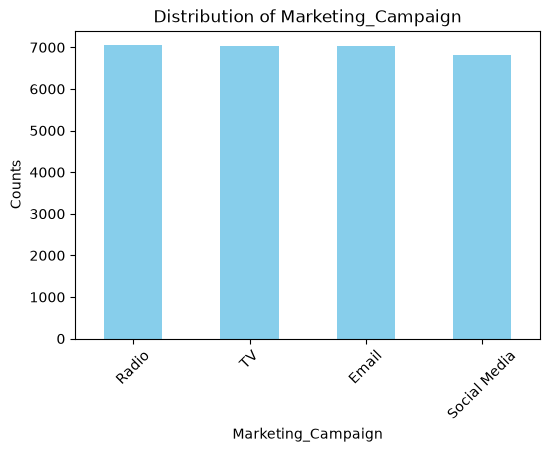

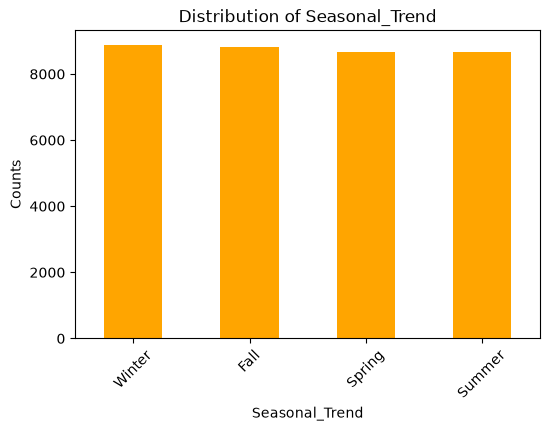

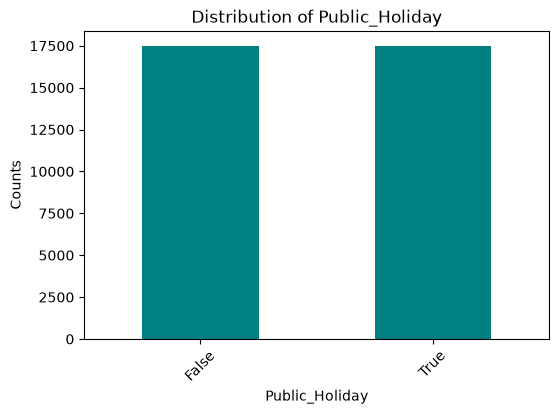

In [15]:
cat_cols = [
    'Marketing_Campaign',
    'Seasonal_Trend',
    'Public_Holiday'
]

colors = ['skyblue', 'orange', 'teal']

for col, c in zip(cat_cols, colors):
    plt.figure(figsize = (6, 4))
    df[col].value_counts().plot(kind='bar', color=c)
    plt.xticks(rotation=45)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Counts")
    plt.show()

### Categorical Features Vs Target

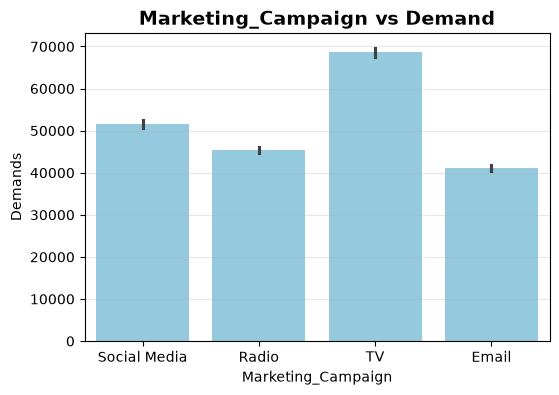

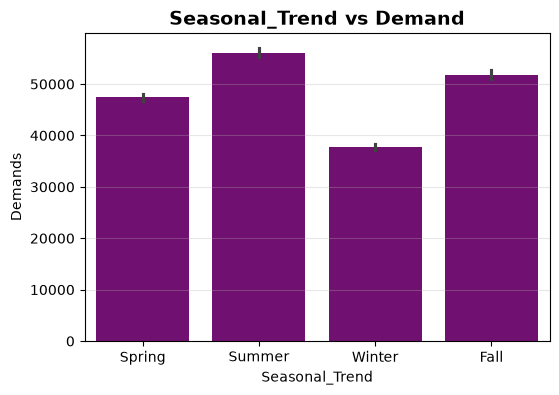

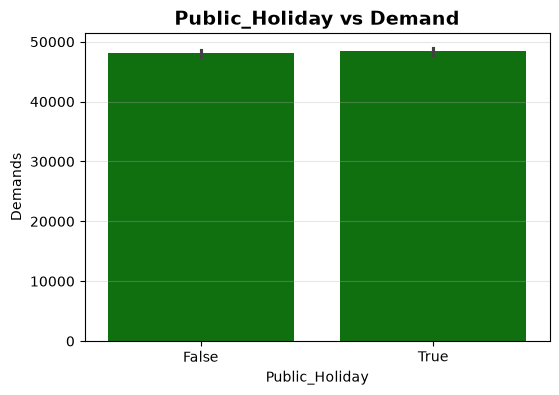

In [16]:
cat_cols = [
    'Marketing_Campaign',
    'Seasonal_Trend',
    'Public_Holiday'
]

colors = ['skyblue', 'purple', 'green']

for col, c in zip(cat_cols, colors):
    plt.figure(figsize = (6, 4))
    sns.barplot(
        data=df,
        x=col,
        y='Demand',
        color=c
    )
    plt.title(f'{col} vs Demand', fontsize=14, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel("Demands")
    plt.grid(axis='y', alpha=0.3)
    plt.show()

### Numerical Features Distribution

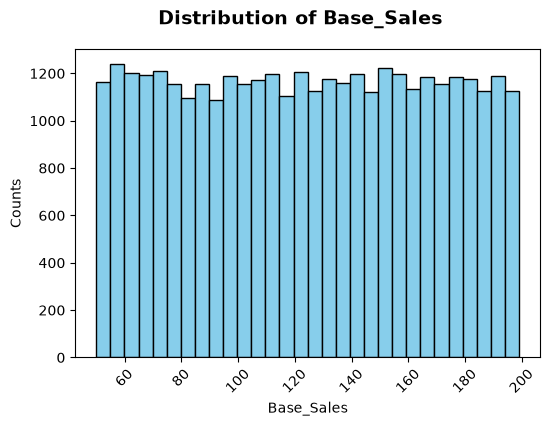

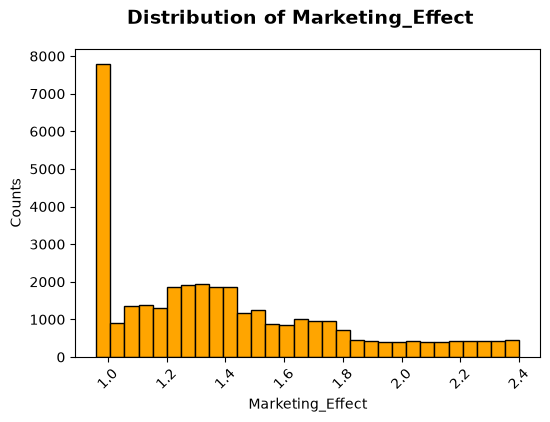

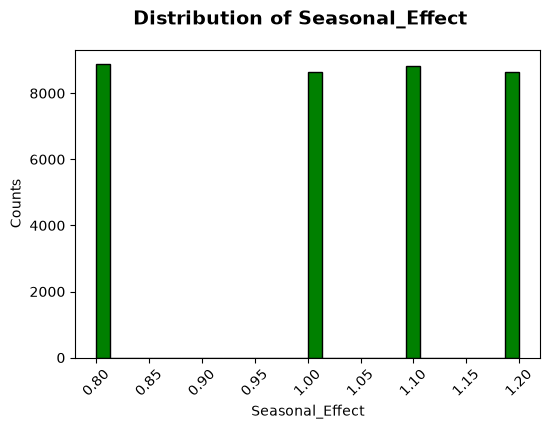

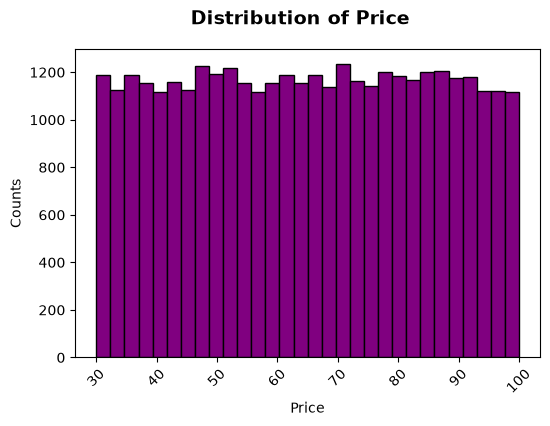

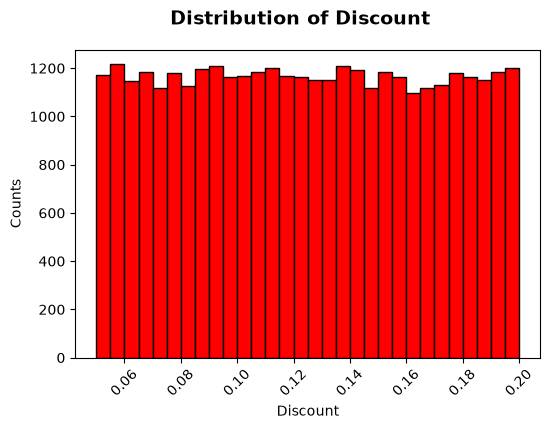

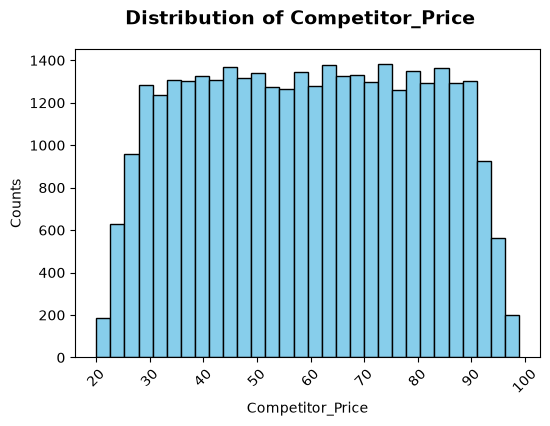

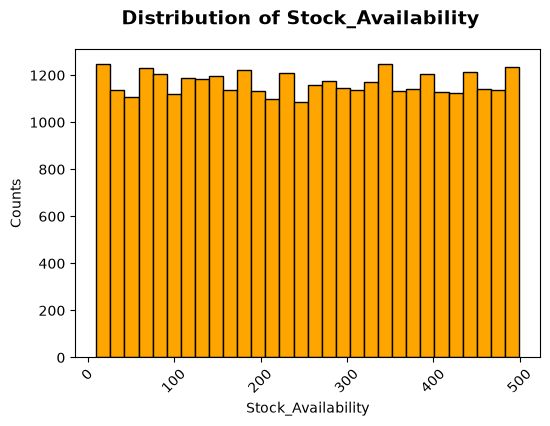

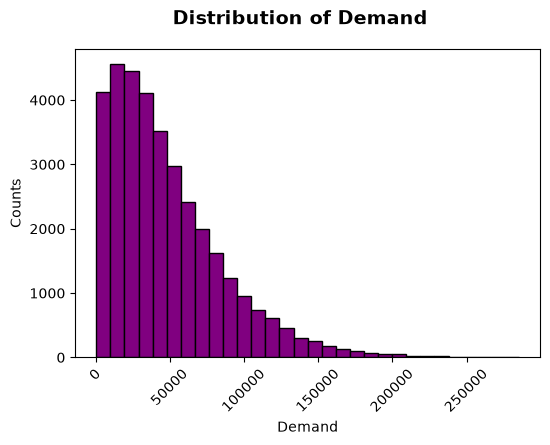

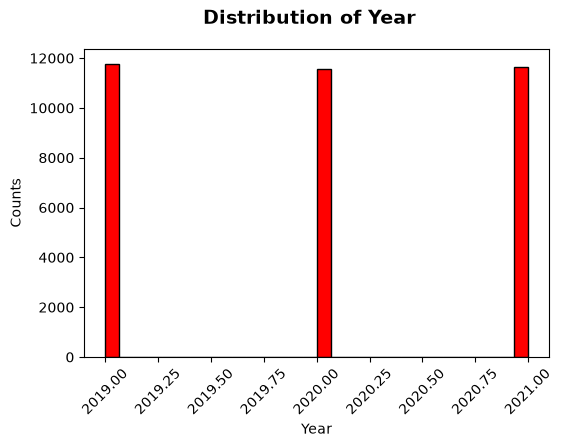

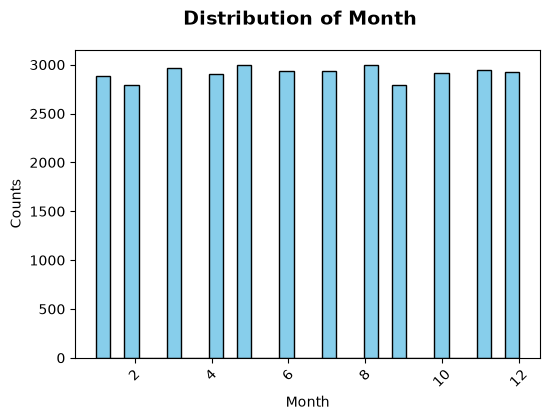

In [17]:
num_cols = [
    'Base_Sales',
    'Marketing_Effect',
    'Seasonal_Effect',
    'Price',
    'Discount',
    'Competitor_Price',
    'Stock_Availability',
    'Demand',
    'Year',
    'Month'
]

colors = ['skyblue', 'orange', 'green', 'purple', 'red', 'skyblue', 'orange', 'purple', 'red', 'skyblue']

for col, c in zip(num_cols, colors):
    plt.figure(figsize = (6, 4))
    plt.suptitle(f'Distribution of {col}', fontsize = 14, fontweight='bold')
    df[col].plot(kind='hist', bins=30, color=c, edgecolor='black')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.xticks(rotation=45)
    plt.show()

### Numerical Features Vs Target

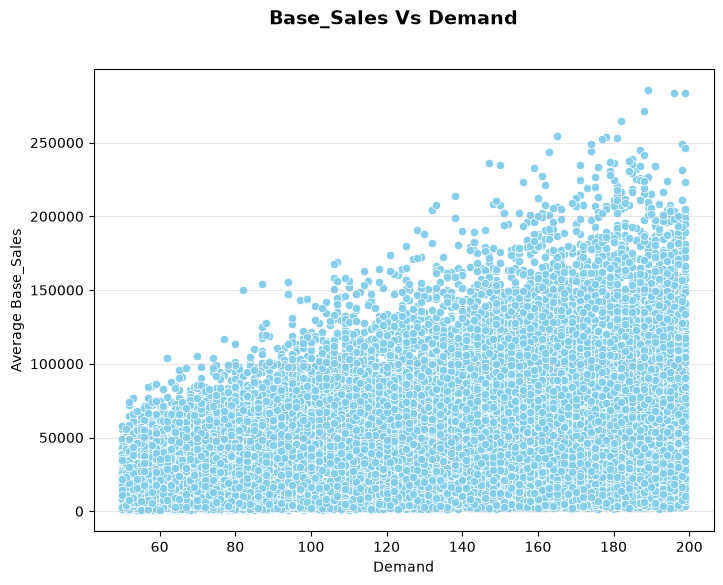

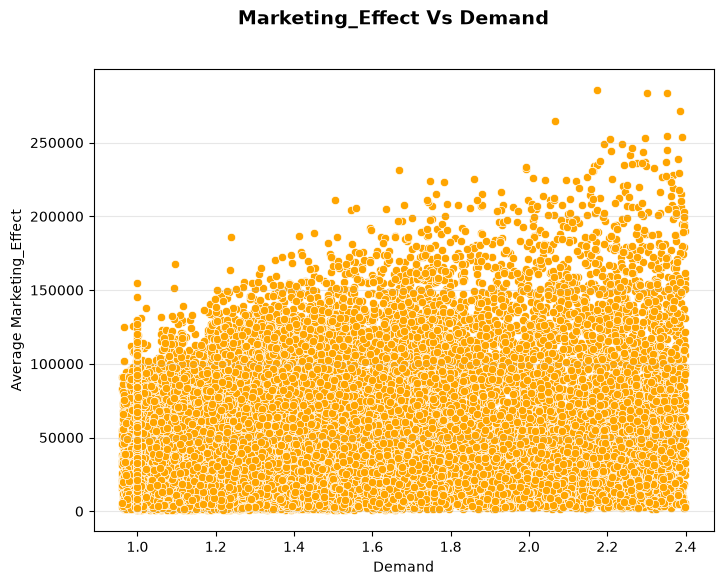

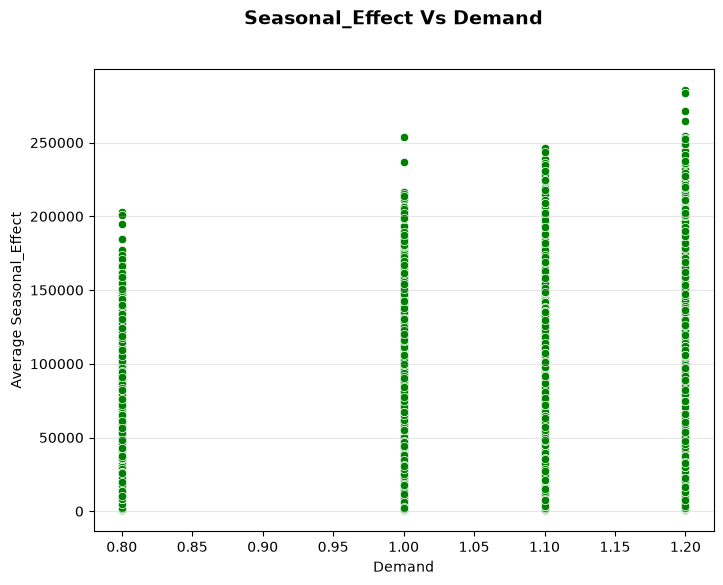

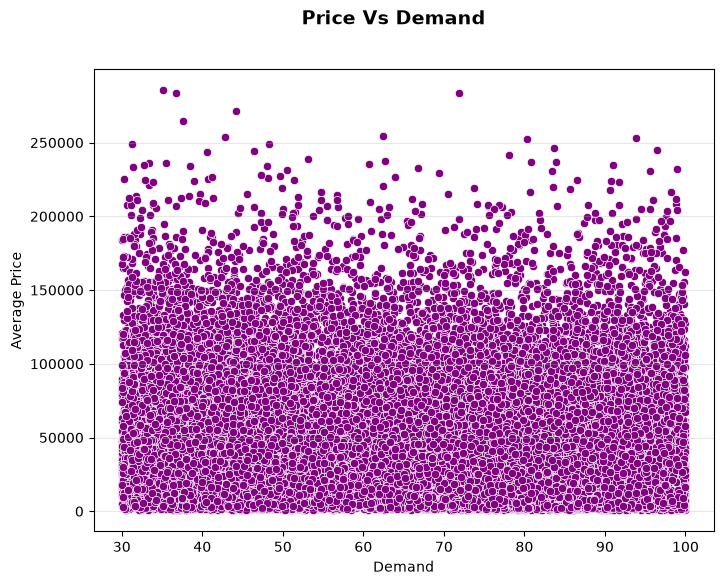

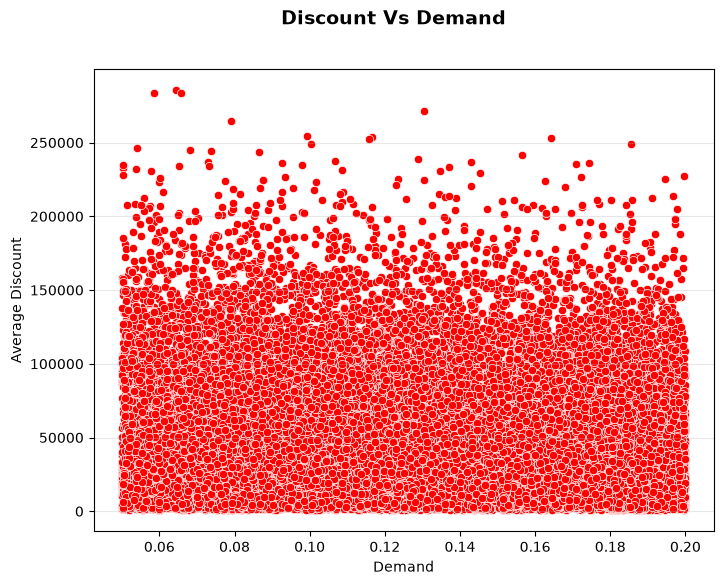

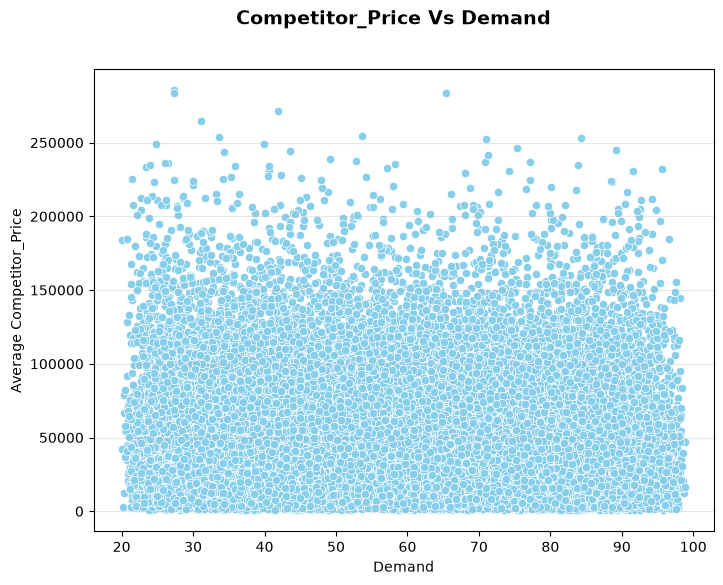

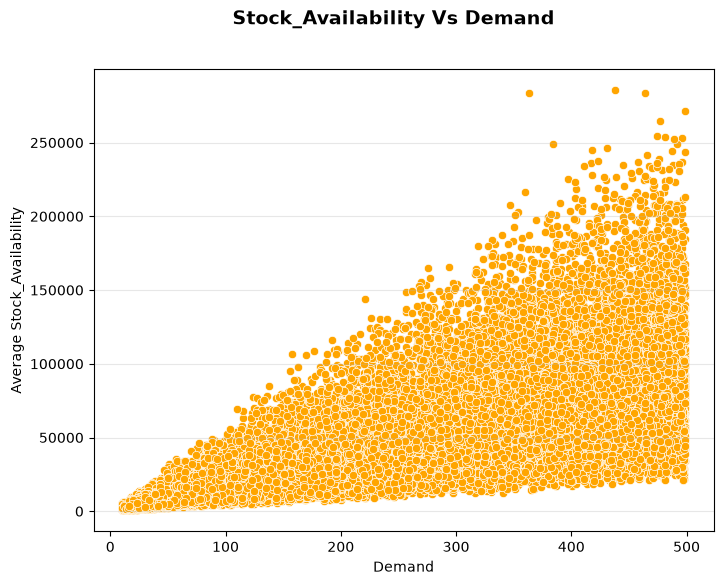

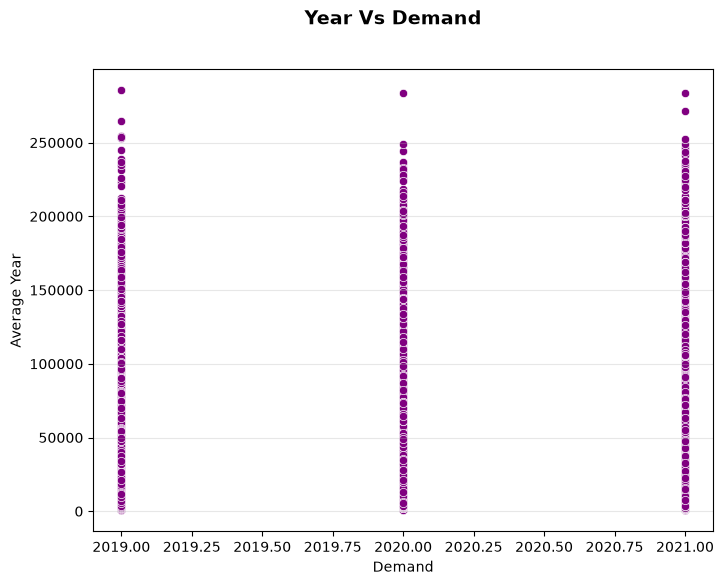

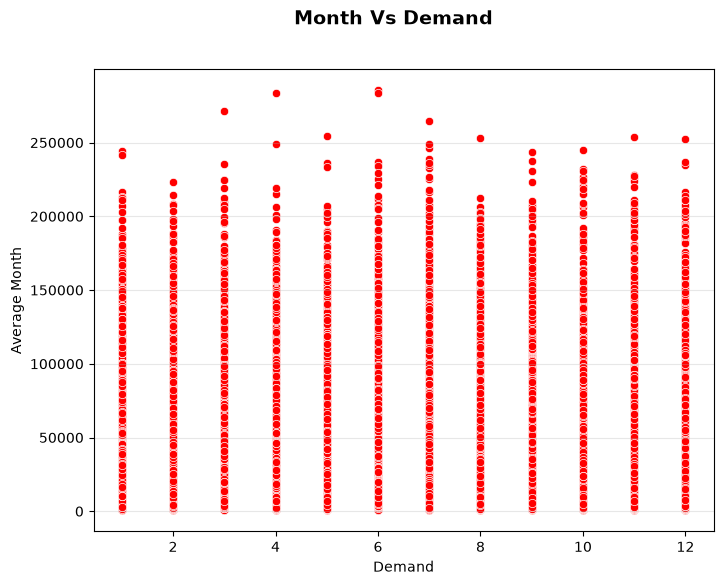

In [18]:
num_cols = [
    'Base_Sales',
    'Marketing_Effect',
    'Seasonal_Effect',
    'Price',
    'Discount',
    'Competitor_Price',
    'Stock_Availability',
    'Year',
    'Month'
]

colors = ['skyblue', 'orange', 'green', 'purple', 'red', 'skyblue', 'orange', 'purple', 'red', 'skyblue']

for col, c in zip(num_cols, colors):
    plt.figure(figsize=(8, 6))
    plt.suptitle(f"{col} Vs Demand", fontsize=14, fontweight='bold')
    sns.scatterplot(data=df, x=col, y='Demand', color=c)
    plt.xlabel('Demand')
    plt.ylabel(f'Average {col}')
    plt.grid(axis='y', alpha=0.3)
    plt.show()

### Heat Map

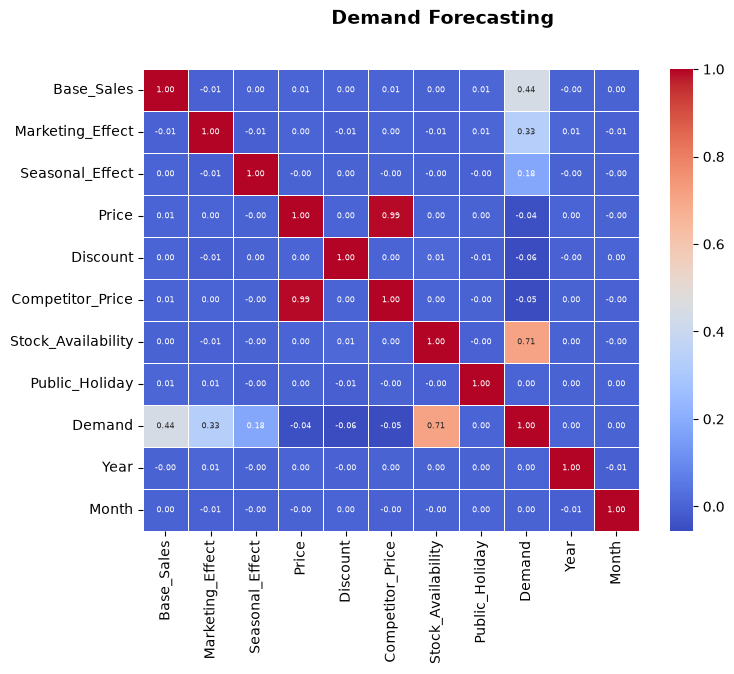

In [19]:
plt.figure(figsize = (8, 6))
sns.heatmap(df.corr(numeric_only=True), annot = True, fmt = '.2f', cmap='coolwarm', linewidth=0.5, annot_kws={'size': 6})
plt.suptitle("Demand Forecasting", fontsize = 14, fontweight='bold')
plt.show()

### Separate Numerical  Vs Categorical Features

In [20]:
num_feature = [feature for feature in df.columns if df[feature].dtype in [np.int64, np.float64]]
cat_feature = [feature for feature in df.columns if df[feature].dtype not in [np.int64, np.float64]]

In [21]:
print("Numerical Features : ", num_feature)
print("Categorical Features : ", cat_feature)

Numerical Features :  ['Base_Sales', 'Marketing_Effect', 'Seasonal_Effect', 'Price', 'Discount', 'Competitor_Price', 'Stock_Availability', 'Demand']
Categorical Features :  ['Marketing_Campaign', 'Seasonal_Trend', 'Public_Holiday', 'Year', 'Month']


### Checking Outliers

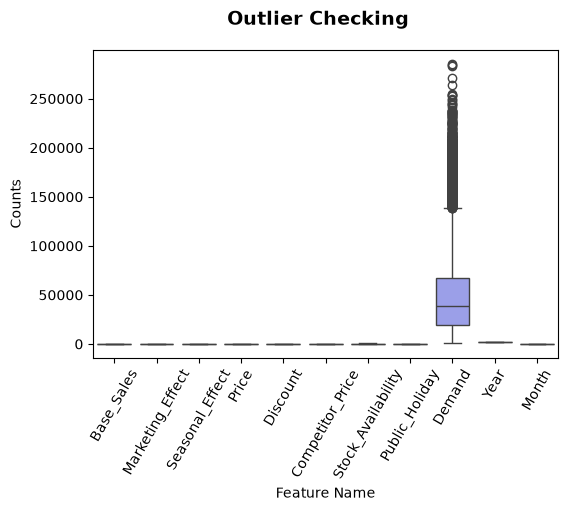

In [22]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df)
plt.xticks(rotation=60)
plt.suptitle("Outlier Checking", fontsize = 14, fontweight='bold')
plt.xlabel("Feature Name")
plt.ylabel("Counts")
plt.show()

### Train Test Split

In [23]:
X = df.drop('Demand', axis=1)
y = df['Demand']

In [24]:
num_feature = X.select_dtypes(include=['int64', 'float64']).columns
cat_feature = X.select_dtypes(include=['object', 'bool']).columns

C:\Users\M Arshad\AppData\Local\Temp\ipykernel_4680\1996243554.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_feature = X.select_dtypes(include=['object', 'bool']).columns


In [25]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

### Preprocessing

In [26]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_feature),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_feature)
])

In [27]:
x_train_scaled = preprocessor.fit_transform(x_train)
x_test_scaled = preprocessor.transform(x_test)

# Machine Learning

### Model Training

In [28]:
!pip install XGBoost


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
import xgboost as xg
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

### Model Traning

In [30]:
models = {
    'XGBoost': XGBRegressor(n_estimators=50),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=23),
    'Linear Regression': LinearRegression(),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Random Forest': RandomForestRegressor(n_estimators=50, random_state=23)
}

for name, model in models.items():
    model.fit(x_train_scaled, y_train)


### Machine Learning Performance

#### Show all Model Performance

In [31]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

best_model = None
best_score = float('-inf')
best_name = ''

for name, model in models.items():

    y_pred = model.predict(x_test_scaled)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    print("\n", name)
    print("R2 Score:", r2)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)

    if r2 > best_score:
        best_score = r2
        best_model = model
        best_name = name


 XGBoost
R2 Score: 0.9912564158439636
MAE: 2343.0517578125
MSE: 12113131.0
RMSE: 3480.3923629384085

 Decision Tree
R2 Score: 0.9499385973949447
MAE: 5357.117814153028
MSE: 69353766.55045068
RMSE: 8327.890882477428

 Linear Regression
R2 Score: 0.8615812435049188
MAE: 9921.427079030753
MSE: 191761749.06442037
RMSE: 13847.806651756096

 KNN
R2 Score: 0.9412094536016513
MAE: 6246.729857142857
MSE: 81446895.57445142
RMSE: 9024.793381260948

 Random Forest
R2 Score: 0.9843324075913855
MAE: 2906.249405714286
MSE: 21705475.47153486
RMSE: 4658.9135505539125


### Final Model Accuracy Score

In [32]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

final_model = best_model
y_pred = final_model.predict(x_test_scaled)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("===== FINAL MODEL PERFORMANCE =====")
print("Final Model:", best_name)
print("Final R2 Score:", r2)
print("Final MAE:", mae)
print("Final MSE:", mse)
print("Final RMSE:", rmse)

===== FINAL MODEL PERFORMANCE =====
Final Model: XGBoost
Final R2 Score: 0.9912564158439636
Final MAE: 2343.0517578125
Final MSE: 12113131.0
Final RMSE: 3480.3923629384085


# Deep Learning

In [33]:
!pip install tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

In [37]:
model = Sequential()

# Input Layer
model.add(Dense(128, activation='relu', input_dim=x_train_scaled.shape[1]))
model.add(Dropout(0.1))
model.add(BatchNormalization())

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1))
model.add(BatchNormalization())

model.add(Dense(32, activation='relu'))
model.add(Dropout(0.1))
model.add(BatchNormalization())

# Output Layer
model.add(Dense(1, activation='linear'))

In [38]:
model.compile(optimizer='adam', loss='mae', metrics=[tf.keras.metrics.R2Score(name='r2_score')])

### Early Stoping

In [39]:
callback = EarlyStopping(
    monitor='val_r2_score',
    min_delta=0.0001,
    patience=10,
    verbose=1,
    mode='max',
    restore_best_weights=True
)

In [40]:
history = model.fit(x_train_scaled, y_train, epochs=100, batch_size=32, validation_data=(x_test_scaled, y_test), callbacks=[callback])

Epoch 1/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 48353.2305 - r2_score: -1.6230 - val_loss: 47623.0664 - val_r2_score: -1.6369
Epoch 2/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 48233.6914 - r2_score: -1.6149 - val_loss: 47452.0195 - val_r2_score: -1.6250
Epoch 3/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 48020.6289 - r2_score: -1.6005 - val_loss: 47199.5000 - val_r2_score: -1.6077
Epoch 4/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 47732.3867 - r2_score: -1.5806 - val_loss: 46877.8711 - val_r2_score: -1.5847
Epoch 5/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 47378.8633 - r2_score: -1.5558 - val_loss: 46489.8906 - val_r2_score: -1.5555
Epoch 6/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 46965.5469 - r2_score: -1.5263 - val_loss: 46007.1719 - val_r2_score: -1.5222
Epoch 7/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 46495.4805 - r2_score: -1.4946 - val_loss: 45542.4727 - val_r2_score: -1.4899
Epoch 8/100
875/875 ━━━━━━━

## R2 Score

In [41]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# DL Performance
dl_score = model.evaluate(x_test_scaled, y_test, verbose=0)

# Predictions
y_pred = model.predict(x_test_scaled, verbose=0)

# Evaluation Metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("===== DEEP LEARNING PERFORMANCE =====")
print("DL R2 Score:", r2)
print("DL MAE:", mae)
print("DL MSE:", mse)
print("DL RMSE:", rmse)

===== DEEP LEARNING PERFORMANCE =====
DL R2 Score: 0.9887577295303345
DL MAE: 2133.501220703125
DL MSE: 15574722.0
DL RMSE: 3946.482231050838


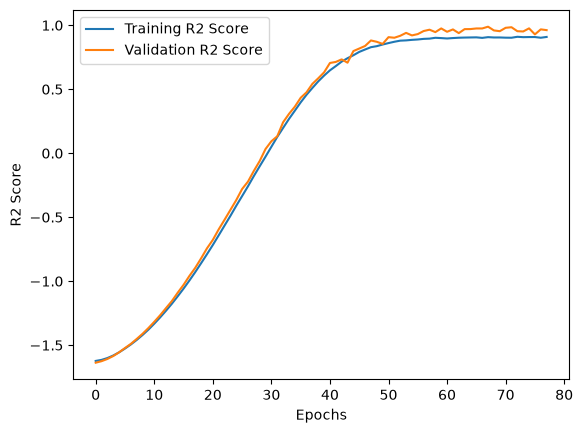

In [42]:
plt.plot(history.history['r2_score'], label='Training R2 Score')
plt.plot(history.history['val_r2_score'], label='Validation R2 Score')
plt.xlabel("Epochs")
plt.ylabel("R2 Score")
plt.legend()
plt.show()

## Loss

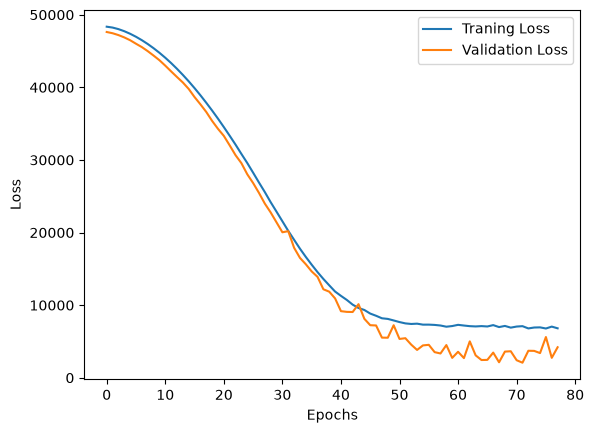

In [43]:
plt.plot(history.history['loss'], label='Traning Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Show ML vs DL performance

In [44]:
print("\n===== ML vs DL PERFORMANCE =====")

print("Best ML Model:", best_name)
print("ML R2 Score:", best_score)

print("Deep Learning R2 Score:", dl_score[1])


===== ML vs DL PERFORMANCE =====
Best ML Model: XGBoost
ML R2 Score: 0.9912564158439636
Deep Learning R2 Score: 0.9887577295303345


In [45]:
import joblib
import json
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Save preprocessing and ML model
joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(best_model, "best_model.pkl")

# Save Deep Learning model
model.save("demand_dl_model.keras")

# Calculate ML predictions and metrics
ml_predictions = best_model.predict(x_test_scaled)

ml_r2 = r2_score(y_test, ml_predictions)
ml_mae = mean_absolute_error(y_test, ml_predictions)
ml_rmse = np.sqrt(mean_squared_error(y_test, ml_predictions))

# Calculate DL predictions and metrics
dl_predictions = model.predict(x_test_scaled, verbose=0).flatten()

dl_r2 = r2_score(y_test, dl_predictions)
dl_mae = mean_absolute_error(y_test, dl_predictions)
dl_rmse = np.sqrt(mean_squared_error(y_test, dl_predictions))

# Save metrics
metrics = {
    "Best ML Model": best_name,
    "ML R2": float(ml_r2),
    "ML MAE": float(ml_mae),
    "ML RMSE": float(ml_rmse),
    "DL R2": float(dl_r2),
    "DL MAE": float(dl_mae),
    "DL RMSE": float(dl_rmse)
}

with open("metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

# Save processed dataset for dashboard
df.to_csv("dashboard_data.csv", index=False)

print("All 5 files saved successfully!")


All 5 files saved successfully!
